# 04 - Model comparison per target

**Goal:** find out whether any model beats the simple logistic baselines of notebook 03 on each target, and settle the questions that had to wait for this comparison.

**Inputs:** `data/raw/*.csv` through `miopia.data.load_raw()`, `clean_features`, and the modules `miopia.validation` and `miopia.models`.

**Outputs:** the model chosen for each target (fitted and used for the test labels in notebook 05), `src/miopia/models.py`, and the figures `04_*.png`.

**Assumptions touched:** B1, B3, B9, B12, B13, B14, B15 and B16, see `docs/assumptions.md`. All targets are trained on their columns as provided (B2). The test set is not used in this notebook.

## 1. Setup and data loading

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import pandas as pd
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import RepeatedStratifiedKFold, TunedThresholdClassifierCV

from miopia.config import RANDOM_STATE, RESULTS
from miopia.data import load_raw
from miopia.features import clean_features, with_axial_corneal_ratio
from miopia.models import CANDIDATES, final_model, ordinal_model, tuned_model, with_tuned_threshold
from miopia.plotting import BLUE, CLASS_COLORS, CLASS_MARKERS, VERMILLION, save_fig, set_style
from miopia.validation import (
    N_REPEATS, SUMMARY_METRICS, evaluate, logistic_baseline, make_strata, selection_test,
)

set_style()
pd.set_option("display.width", 160)
TARGETS = ["M", "MM", "Combo", "DCombo"]
SECOND_SEED = RANDOM_STATE + 1
X_train_raw, Y_train, _ = load_raw()     # the test rows are not needed here
X_train = clean_features(X_train_raw)
strata = {t: make_strata(Y_train, t) for t in TARGETS}
print(f"train {X_train.shape}")

train (132, 33)


## 2. Which rules decide the winner?

These rules were written before any model in this notebook was run (B14), with two exceptions: route B, explained under *Test to pass*, and the repeated inner split used to tune the `MM` threshold (section 8).

- **Candidates.** Tuned logistic regression, an SVM with an RBF kernel, a random forest and XGBoost, all on the 33 features. Linear, kernel and two kinds of tree ensemble cover different shapes of relationship.
- **Nested cross-validation.** The outer loop is the 5-fold, 10-repeat scheme of notebook 03. Inside each outer training set, a grid search with 3 folds picks the hyperparameters by balanced accuracy. The outer validation rows are never seen by the search, so the outer scores are not inflated by trying many settings. The grids are small on purpose, since 132 students cannot support a large search.
- **Reference.** For each target, whichever logistic baseline of notebook 03 has the higher balanced accuracy.
- **Test to pass.** A candidate passes by either of two routes. Route A: balanced accuracy clearly better than the reference (B12), and macro-F1 not clearly worse; if macro-F1 is clearly worse, accuracy decides and must be clearly better (B13). Route B: balanced accuracy not clearly worse, and both macro-F1 and accuracy clearly better. Route B was added after seeing the first validation results, because route A alone rejected a model that was clearly worse on no metric and clearly better on two. It relaxes the requirement stated in notebook 03, which asked for clearly better balanced accuracy. The test set played no part in this, but a rule adjusted after seeing validation scores can make those scores somewhat optimistic.
- **Winner.** Among those that pass, the highest balanced accuracy, which must pass again on a second set of folds. If nothing passes, the reference stays. The second set of folds uses the same students, so it only guards against the luck of one split.

"Clearly" keeps the meaning given in notebook 03: a stability check across new splits of the same students, not evidence about new students. Section 11 measures how often this test passes for useless information, and it does so too often on some targets.

## 3. What is XGBoost, and why try it?

XGBoost was not covered in class, so here is what it does. It builds many small decision trees one after another. Each new tree is fitted to correct the errors of the trees before it, and its contribution is scaled down by the learning rate, so the model improves in small steps. A random forest, by contrast, grows its trees independently and averages them.

XGBoost is known for doing well on tabular data, and it can capture interactions between features without being told about them. The risk with 132 students is overfitting, so we limit it: shallow trees (depth 2 or 3), a small grid, and each tree sees only part of the students and of the features. We also weight the classes to match the other candidates. Trees do not need scaling, so only the median imputation is applied.

## 4. How do the candidates score?

**What and why:** every candidate runs through the nested scheme on every target, on the same outer folds as the two logistic baselines, so the comparisons are paired.

In [2]:
def run_all(seed=RANDOM_STATE):
    frames, predictions = {}, {}
    baselines = {"Logistic, axial length only": (logistic_baseline(), X_train[["axial_length"]]),
                 "Logistic, all 33 features": (logistic_baseline(), X_train)}
    models = {**baselines, **{name: (tuned_model(name), X_train) for name in CANDIDATES}}
    for target in TARGETS:
        for name, (model, data) in models.items():
            frame, pred = evaluate(model, data, Y_train[target], Y_train[target], strata[target], seed=seed)
            frames[target, name], predictions[target, name] = frame, pred
    return frames, predictions

frames, predictions = run_all()
scores = pd.DataFrame({key: frame[SUMMARY_METRICS].mean() for key, frame in frames.items()}).T
scores.insert(1, "balanced_accuracy_sd", [frame["balanced_accuracy"].std() for frame in frames.values()])
scores.index.names = ["target", "model"]
scores.round(2)

balanced_accuracy  balanced_accuracy_sd  macro_f1  accuracy   mcc
target model                                                                                         
M      Logistic, axial length only               0.77                  0.08      0.75      0.77  0.52
       Logistic, all 33 features                 0.77                  0.09      0.76      0.78  0.53
       Logistic, tuned                           0.75                  0.09      0.74      0.77  0.50
       SVM (RBF)                                 0.71                  0.09      0.70      0.73  0.43
       Random forest                             0.73                  0.09      0.72      0.76  0.47
       XGBoost                                   0.74                  0.08      0.73      0.76  0.48
MM     Logistic, axial length only               0.81                  0.14      0.65      0.82  0.40
       Logistic, all 33 features                 0.79                  0.17      0.74      0.91  0.50
       Logistic, tuned                           0.77                  0.18      0.70      0.88  0.43
       SVM (RBF)                                 0.75                  0.18      0.68      0.89  0.41
       Random forest                             0.61                  0.16      0.61      0.92  0.24
       XGBoost                                   0.68                  0.14      0.67      0.91  0.36
Combo  Logistic, axial length only               0.71                  0.07      0.66      0.65  0.45
       Logistic, all 33 features                 0.68                  0.11      0.66      0.66  0.45
       Logistic, tuned                           0.65                  0.10      0.60      0.61  0.39
       SVM (RBF)                                 0.66                  0.12      0.65      0.65  0.43
       Random forest                             0.73                  0.09      0.73      0.71  0.52
       XGBoost                                   0.73                  0.09      0.73      0.71  0.52
DCombo Logistic, axial length only               0.60                  0.08      0.58      0.56  0.41
       Logistic, all 33 features                 0.51                  0.09      0.50      0.49  0.31
       Logistic, tuned                           0.49                  0.08      0.47      0.48  0.29
       SVM (RBF)                                 0.49                  0.08      0.49      0.49  0.30
       Random forest                             0.59                  0.09      0.59      0.56  0.40
       XGBoost                                   0.56                  0.08      0.55      0.53  0.36

Each point is one validation fold. The vermilion dots mark the reference of that target.

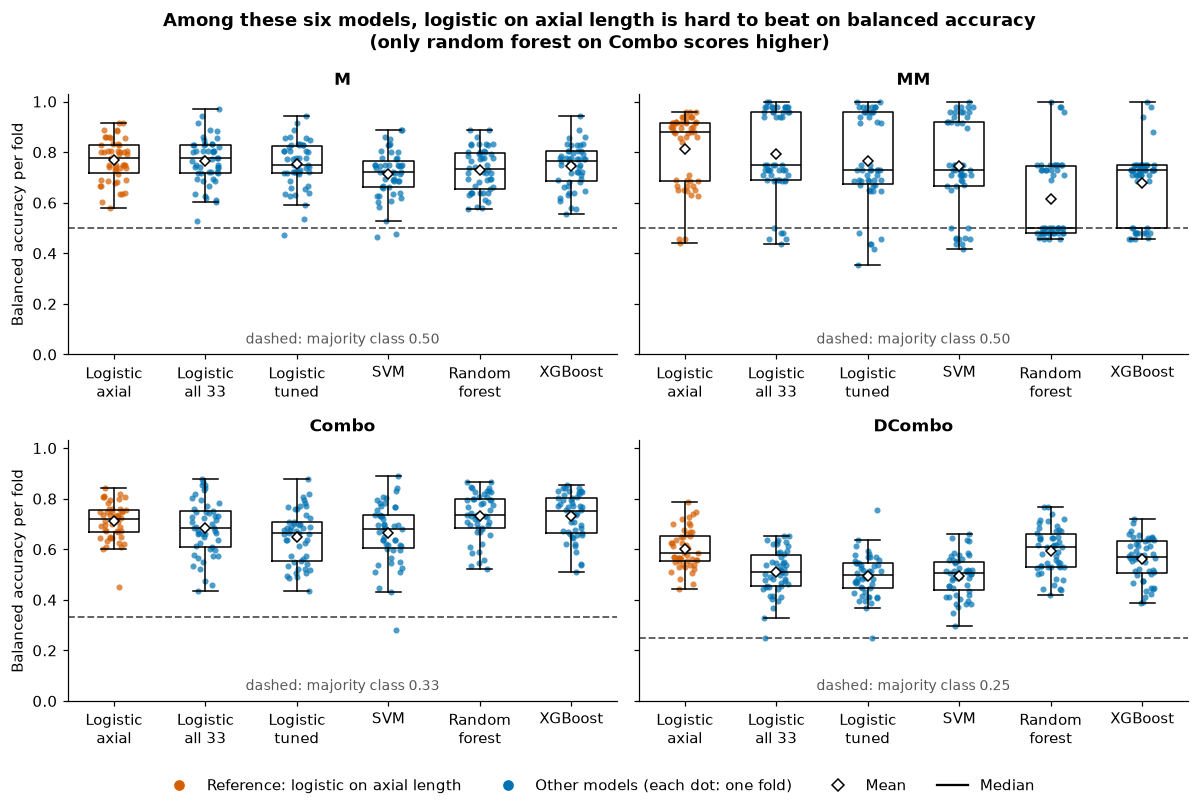

In [3]:
references = {t: scores.loc[t].loc[[n for n in scores.loc[t].index if n.startswith("Logistic,") and n != "Logistic, tuned"],
                                  "balanced_accuracy"].idxmax() for t in TARGETS}
names = list(scores.loc["M"].index)
short = {"Logistic, axial length only": "Logistic\naxial", "Logistic, all 33 features": "Logistic\nall 33",
         "Logistic, tuned": "Logistic\ntuned", "SVM (RBF)": "SVM", "Random forest": "Random\nforest", "XGBoost": "XGBoost"}
rng = np.random.default_rng(0)
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharey=True)
for ax, target in zip(axes.ravel(), TARGETS):
    for x, name in enumerate(names):
        values = frames[target, name]["balanced_accuracy"]
        color = VERMILLION if name == references[target] else BLUE
        ax.scatter(x + rng.uniform(-0.15, 0.15, len(values)), values, s=16, color=color, alpha=0.7, linewidths=0)
        ax.boxplot(values, positions=[x], widths=0.55, showfliers=False, medianprops={"color": "black"}, showmeans=True,
                   meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black", "markersize": 5})
    chance = 1 / Y_train[target].nunique()
    ax.axhline(chance, color="0.35", ls="--", lw=1.2, zorder=0)
    ax.text(2.5, 0.03, f"dashed: majority class {chance:.2f}", ha="center", va="bottom", fontsize=9, color="0.35")
    ax.set_xticks(range(len(names)), [short[n] for n in names])
    ax.set_ylim(0, 1.03)
    ax.set_title(target)
for ax in axes[:, 0]:
    ax.set_ylabel("Balanced accuracy per fold")
fig.suptitle('Among these six models, logistic on axial length is hard to beat on balanced accuracy\n(only random forest on Combo scores higher)', fontweight="bold")
fig.tight_layout()
fig.legend(handles=[
    Line2D([], [], marker="o", ls="", color=VERMILLION, label="Reference: logistic on axial length"),
    Line2D([], [], marker="o", ls="", color=BLUE, label="Other models (each dot: one fold)"),
    Line2D([], [], marker="D", ls="", markerfacecolor="white", markeredgecolor="black", label="Mean"),
    Line2D([], [], color="black", label="Median"),
], loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=4)
save_fig(fig, "04_model_comparison")
plt.show()

**Findings.** On balanced accuracy, logistic regression on axial length alone is the best or close to it on every target; only the random forest and XGBoost on `Combo` are higher, and they are level with each other. On the other three targets XGBoost falls behind the axial model. Tuning the logistic regression does not help: it scores below the default on all four targets. On `MM`, the two tree ensembles reach about the accuracy of the majority class but have low balanced accuracy, which means they rarely say `SI`. The spread between folds is wide, so only the paired comparison below can tell small gaps apart.

## 5. Does any candidate pass the test?

**What and why:** each candidate is compared with the reference of its target, repeat by repeat. Only candidates that pass can win.

In [4]:
rows = {(t, name): selection_test(frames[t, name], frames[t, references[t]])
        for t in TARGETS for name in names if name != references[t]}
tests = pd.DataFrame(rows).T
tests.index.names = ["target", "compared with its reference"]
print("Reference of each target:", references)
display(tests.apply(lambda c: c.astype(float).round(3) if c.name.endswith("difference") else c))

first_round = {}
for target in TARGETS:
    passing = tests.loc[target][tests.loc[target]["passes"]].index
    first_round[target] = scores.loc[target].loc[passing, "balanced_accuracy"].idxmax() if len(passing) else None
print("Passes on the first set of folds:", first_round)
n_tests = len(tests)

Reference of each target: {'M': 'Logistic, axial length only', 'MM': 'Logistic, axial length only', 'Combo': 'Logistic, axial length only', 'DCombo': 'Logistic, axial length only'}


balanced_accuracy: difference balanced_accuracy: verdict  macro_f1: difference    macro_f1: verdict  accuracy: difference  \
target compared with its reference                                                                                                                              
M      Logistic, all 33 features                           -0.002        no clear difference                 0.005  no clear difference                 0.008   
       Logistic, tuned                                     -0.016        no clear difference                -0.009  no clear difference                -0.005   
       SVM (RBF)                                           -0.054              clearly worse                -0.051        clearly worse                -0.040   
       Random forest                                       -0.037              clearly worse                -0.027        clearly worse                -0.017   
       XGBoost                                             -0.024              clearly worse                -0.021        clearly worse                -0.015   
MM     Logistic, all 33 features                           -0.019        no clear difference                 0.091       clearly better                 0.091   
       Logistic, tuned                                     -0.046        no clear difference                 0.052       clearly better                 0.059   
       SVM (RBF)                                           -0.065              clearly worse                 0.038  no clear difference                 0.066   
       Random forest                                       -0.198              clearly worse                -0.036  no clear difference                 0.093   
       XGBoost                                             -0.136              clearly worse                 0.023  no clear difference                 0.088   
Combo  Logistic, all 33 features                           -0.027        no clear difference                -0.001  no clear difference                 0.011   
       Logistic, tuned                                     -0.061              clearly worse                -0.052        clearly worse                -0.043   
       SVM (RBF)                                           -0.046              clearly worse                -0.009  no clear difference                 0.000   
       Random forest                                        0.020             clearly better                 0.077       clearly better                 0.065   
       XGBoost                                              0.021             clearly better                 0.079       clearly better                 0.063   
DCombo Logistic, all 33 features                           -0.091              clearly worse                -0.082        clearly worse                -0.073   
       Logistic, tuned                                     -0.106              clearly worse                -0.105        clearly worse                -0.087   
       SVM (RBF)                                           -0.107              clearly worse                -0.088        clearly worse                -0.077   
       Random forest                                       -0.007        no clear difference                 0.013  no clear difference                 0.002   
       XGBoost                                             -0.041              clearly worse                -0.024  no clear difference                -0.034   

                                      accuracy: verdict passes route  
target compared with its reference                                    
M      Logistic, all 33 features    no clear difference  False        
       Logistic, tuned              no clear difference  False        
       SVM (RBF)                          clearly worse  False        
       Random forest                no clear difference  False        
       XGBoost                            clearly worse  False     

Passes on the first set of folds: {'M': None, 'MM': 'Logistic, all 33 features', 'Combo': 'XGBoost', 'DCombo': None}


A result on one set of folds can be luck, so each candidate that came first is run again on new folds, with the reference, and must pass again.

In [5]:
# The catalog also lists the ratio and ordinal options, which section 6 explains.
X_ratio = with_axial_corneal_ratio(X_train)
FEATURES = list(X_train.columns)
catalog = {"Logistic, axial length only": (logistic_baseline, ["axial_length"]),
           "Logistic, all 33 features": (logistic_baseline, FEATURES),
           **{n: (lambda n=n: tuned_model(n), FEATURES) for n in CANDIDATES},
           "Logistic, ratio only": (logistic_baseline, ["axial_corneal_ratio"]),
           "Logistic, axial + ratio": (logistic_baseline, ["axial_length", "axial_corneal_ratio"]),
           "Logistic, all 33 + ratio": (logistic_baseline, FEATURES + ["axial_corneal_ratio"]),
           "Random forest + ratio": (lambda: tuned_model("Random forest"), FEATURES + ["axial_corneal_ratio"]),
           "Ordinal, axial": (ordinal_model, ["axial_length"]),
           "Ordinal, axial + ratio": (ordinal_model, ["axial_length", "axial_corneal_ratio"])}

def run_model(target, name, seed=RANDOM_STATE):
    factory, columns = catalog[name]
    return evaluate(factory(), X_ratio[columns], Y_train[target], Y_train[target], strata[target], seed=seed)

winners, second_round = {}, {}
for target in TARGETS:
    winners[target] = references[target]
    if first_round[target]:
        new, _ = run_model(target, first_round[target], SECOND_SEED)
        reference, _ = run_model(target, references[target], SECOND_SEED)
        second_round[target] = selection_test(new, reference)
        if second_round[target]["passes"]:
            winners[target] = first_round[target]
if second_round:
    display(pd.DataFrame(second_round).T)
final = pd.DataFrame({t: scores.loc[(t, winners[t])] for t in TARGETS}).T.astype(float).round(2)
final.insert(0, "chosen model", [winners[t] for t in TARGETS])
final

,balanced_accuracy: difference,balanced_accuracy: verdict,macro_f1: difference,macro_f1: verdict,accuracy: difference,accuracy: verdict,passes,route
MM,-0.0126,no clear difference,0.090448,clearly better,0.095385,clearly better,True,B
Combo,0.001878,no clear difference,0.052506,clearly better,0.037236,clearly better,True,B


,chosen model,balanced_accuracy,balanced_accuracy_sd,macro_f1,accuracy,mcc
M,"Logistic, axial length only",0.77,0.08,0.75,0.77,0.52
MM,"Logistic, all 33 features",0.79,0.17,0.74,0.91,0.50
Combo,XGBoost,0.73,0.09,0.73,0.71,0.52
DCombo,"Logistic, axial length only",0.60,0.08,0.58,0.56,0.41


**Findings.** Nothing passes on `M` or `DCombo`, so the axial model stays. On `MM`, the full logistic regression passes by route B on both sets of folds: balanced accuracy shows no clear difference, while macro-F1 and accuracy are clearly better. On `Combo`, the random forest and XGBoost both pass by route A, with almost the same gain; XGBoost comes first by a very small margin. It passes again by route B on the second set of folds, so its gain on balanced accuracy is less firm than its gain on the other two metrics. *These choices are provisional: they are the reference for the experiments in section 6.*

## 6. Can medical knowledge or the order of the classes improve on this?

**What and why:** these two experiments were written down before being run (B15). They come from two limits seen above. The simple references use only the length of the eye, although the eye focuses through its length and its cornea together. And `C`, `M1`, `M2` and `MM` have a natural order that the models so far ignore.

**The axial/corneal ratio.** A person becomes myopic when the eye is too long for the power of the cornea, so the ratio of axial length to corneal radius combines both. The literature describes it as a marker of refractive state:

- Yebra-Pimentel et al. (2004), in 193 university students with a mean age of 22, report a mean ratio that rises with myopia: 3.01 in low, 3.10 in moderate and 3.23 in high myopia, against 2.98 in emmetropes. It is the closest population to ours.
- Fan, Huang and Huang (2024), in 187 adult patients who were all myopic, report that the ratio is more strongly related to refractive error than axial length alone. Their introduction notes, citing earlier work, that a value of 3 is described in children and adolescents as the point where the cornea can no longer compensate. Because all their patients are myopic, this does not directly address telling myopic from non-myopic students.

The brief does not state the units of the keratometry columns. We deduced that they are in dioptres, from the checks printed below (B16). They are converted with the standard formula, radius = 337.5 / dioptres, using the mean of the four values, which notebook 02 showed to be near duplicates. The ratio is computed row by row without labels, so it leaks nothing. We use the published ratio as an idea to test here, not as a fixed cut-off.

**The ordinal model.** A proportional-odds logistic regression, also not covered in class, learns one severity score and cuts it into ordered classes. If `M` and `Combo` are derived from it, those targets cannot contradict `DCombo`. Class weights are balanced to match the other candidates.

**References**
- Yebra-Pimentel E, Giráldez MJ, Glez.-Méijome JM, Cerviño A, García-Resúa C, Parafita MA. Variation of the axial length/corneal radius ratio with ocular refractive status (title translated from Spanish). *Archivos de la Sociedad Española de Oftalmología* 2004;79(7):317-324. [Record](https://investigacion.usc.gal/documentos/5d1df6ec29995204f767c908?lang=en)
- Fan, Huang, Huang. Association between Axial Length to Corneal Curvature Radius Ratio and Myopia in Adult Patients. *Journal of Ophthalmology*, 2024. [PMC10917480](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC10917480/)
- Keratometry, SPIE Optipedia. [Link](https://lux.spie.org/publications/spie-publication-resources/optipedia-free-optics-information/fg04_p42_keratometry)

First, the deduction about the units. Values near 40 cannot be a radius in millimetres, which is close to 8. If they are dioptres, the converted radius should be a typical human value, the two readings of each eye should differ by a normal astigmatism, and longer eyes should tend to have flatter corneas.

In [6]:
readings = X_train[["kerato_od", "kerato_od_axis2", "kerato_os", "kerato_os_axis2"]]
mean_k = readings.mean(axis=1)
print(f"keratometry range: {readings.min().min():.1f} to {readings.max().max():.1f}")
print(f"radius if dioptres: mean {(337.5 / mean_k).mean():.2f} mm, range {(337.5 / mean_k).min():.2f} to {(337.5 / mean_k).max():.2f} mm")
for eye in ["od", "os"]:
    gap = readings[f"kerato_{eye}_axis2"] - readings[f"kerato_{eye}"]
    print(f"{eye}: second reading >= first in {(gap >= 0).mean():.0%} of students, mean difference {gap.mean():.2f}")
print(f"correlation of mean keratometry with axial length: {mean_k.corr(X_train['axial_length']):.2f}")

keratometry range: 36.5 to 48.4
radius if dioptres: mean 7.80 mm, range 7.13 to 9.07 mm
od: second reading >= first in 100% of students, mean difference 0.98
os: second reading >= first in 100% of students, mean difference 1.00
correlation of mean keratometry with axial length: -0.46


**Findings.** All four checks fit dioptres, so we work with that deduction. It remains a deduction, because no document confirms the units. Does the ratio then behave in our data as the literature describes? The figure uses all training students.

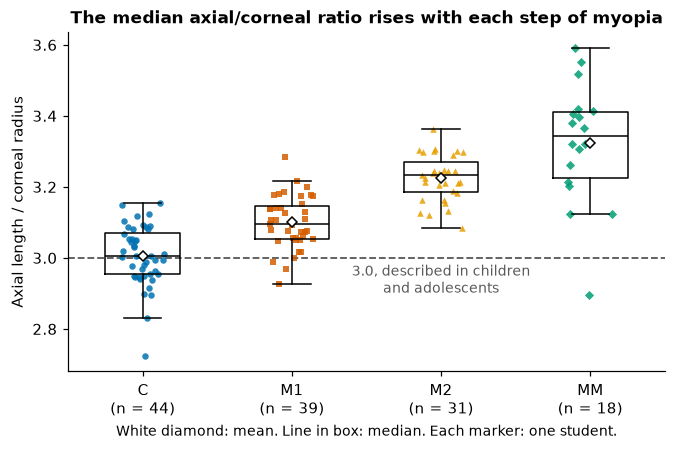

,count,mean
DCombo,,
C,44,3.01
M1,39,3.10
M2,31,3.23
MM,18,3.32


In [7]:
RATIO = "axial_corneal_ratio"
fig, ax = plt.subplots(figsize=(7, 4))
order = ["C", "M1", "M2", "MM"]
for x, cls in enumerate(order):
    values = X_ratio.loc[Y_train["DCombo"] == cls, RATIO]
    ax.scatter(x + rng.uniform(-0.15, 0.15, len(values)), values, s=18, alpha=0.85, linewidths=0,
               color=CLASS_COLORS["DCombo"][cls], marker=CLASS_MARKERS[cls])
    ax.boxplot(values, positions=[x], widths=0.5, showfliers=False, medianprops={"color": "black"}, showmeans=True,
               meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black", "markersize": 5})
ax.axhline(3, color="0.35", ls="--", lw=1.2, zorder=0)
ax.text(2, 2.985, "3.0, described in children\nand adolescents", ha="center", va="top", fontsize=9, color="0.35")
counts = Y_train["DCombo"].value_counts()
ax.set_xticks(range(4), [f"{c}\n(n = {counts[c]})" for c in order])
ax.set_ylabel("Axial length / corneal radius")
ax.set_xlabel("White diamond: mean. Line in box: median. Each marker: one student.", fontsize=9)
ax.set_title("The median axial/corneal ratio rises with each step of myopia")
save_fig(fig, "04_ratio_by_class")
plt.show()
X_ratio.groupby(Y_train["DCombo"])[RATIO].agg(["count", "mean"]).reindex(order).round(2)

Now each option runs on the folds of its target and is compared with the model chosen in section 5, with the same test. Options derived from the ordinal model use the folds of `DCombo`, so they are compared per repeat and not on the same folds.

In [8]:
def repeat_scores(predicted, truth):
    rows = []
    for repeat in range(N_REPEATS):
        p = predicted[:, repeat]
        rows.append({"repeat": repeat, "balanced_accuracy": balanced_accuracy_score(truth, p),
                     "macro_f1": f1_score(truth, p, average="macro"), "accuracy": accuracy_score(truth, p)})
    return pd.DataFrame(rows)

def derive(dcombo, target):
    return np.where(dcombo == "C", "NO", "SI") if target == "M" else np.where(np.isin(dcombo, ["M1", "M2"]), "M", dcombo)

options = {"M": ["Logistic, ratio only", "Logistic, axial + ratio"],
           "MM": ["Logistic, ratio only", "Logistic, axial + ratio", "Logistic, all 33 + ratio"],
           "Combo": ["Logistic, ratio only", "Logistic, axial + ratio", "Random forest + ratio"],
           "DCombo": ["Logistic, ratio only", "Logistic, axial + ratio", "Ordinal, axial", "Ordinal, axial + ratio"]}
ORDINALS = ["Ordinal, axial", "Ordinal, axial + ratio"]

def score_option(target, name, seed):
    """Fold scores and predictions of an option; derived targets are scored per repeat."""
    if name.startswith("Derived from "):
        _, dcombo = run_model("DCombo", name.removeprefix("Derived from "), seed)
        predicted = derive(dcombo, target)
        return repeat_scores(predicted, Y_train[target]), predicted
    return run_model(target, name, seed)

def reference_for(target, name, frame, pred):
    return repeat_scores(pred, Y_train[target]) if name.startswith("Derived from ") else frame

rows, option_frames, option_predictions = {}, {}, {}
for target in TARGETS:
    names = options[target] + ([f"Derived from {o}" for o in ORDINALS] if target in ("M", "Combo") else [])
    for name in names:
        frame, pred = score_option(target, name, RANDOM_STATE)
        option_frames[target, name], option_predictions[target, name] = frame, pred
        rows[target, name] = {"mean balanced accuracy": frame["balanced_accuracy"].mean(),
                              **selection_test(frame, reference_for(target, name, frames[target, winners[target]], predictions[target, winners[target]]))}
option_tests = pd.DataFrame(rows).T
display(option_tests.apply(lambda c: c.astype(float).round(3) if c.name.endswith("difference") or c.name.startswith("mean") else c))
n_tests += len(option_tests)

mean balanced accuracy  balanced_accuracy: difference balanced_accuracy: verdict  macro_f1: difference  \
M      Logistic, ratio only                                  0.795                          0.028             clearly better                 0.022   
       Logistic, axial + ratio                               0.805                          0.037             clearly better                 0.032   
       Derived from Ordinal, axial                           0.739                         -0.029              clearly worse                -0.009   
       Derived from Ordinal, axial + ratio                   0.758                         -0.010        no clear difference                 0.010   
MM     Logistic, ratio only                                  0.891                          0.098             clearly better                 0.008   
       Logistic, axial + ratio                               0.847                          0.055             clearly better                -0.050   
       Logistic, all 33 + ratio                              0.821                          0.028             clearly better                 0.033   
Combo  Logistic, ratio only                                  0.673                         -0.058              clearly worse                -0.115   
       Logistic, axial + ratio                               0.736                          0.005        no clear difference                -0.046   
       Random forest + ratio                                 0.770                          0.039             clearly better                 0.033   
       Derived from Ordinal, axial                           0.752                          0.021             clearly better                 0.014   
       Derived from Ordinal, axial + ratio                   0.740                          0.009        no clear difference                 0.006   
DCombo Logistic, ratio only                                  0.611                          0.010        no clear difference                 0.021   
       Logistic, axial + ratio                               0.653                          0.051             clearly better                 0.062   
       Ordinal, axial                                        0.635                          0.034             clearly better                 0.052   
       Ordinal, axial + ratio                                0.623                          0.022             clearly better                 0.042   

                                              macro_f1: verdict  accuracy: difference    accuracy: verdict passes route  
M      Logistic, ratio only                      clearly better                 0.016       clearly better   True     A  
       Logistic, axial + ratio                   clearly better                 0.026       clearly better   True     A  
       Derived from Ordinal, axial          no clear difference                 0.008  no clear difference  False        
       Derived from Ordinal, axial + ratio  no clear difference                 0.023       clearly better  False        
MM     Logistic, ratio only                 no clear difference                -0.031        clearly worse   True     A  
       Logistic, axial + ratio                    clearly worse                -0.060        clearly worse  False        
       Logistic, all 33 + ratio                  clearly better                 0.010       clearly better   True     A  
Combo  Logistic, ratio only                       clearly worse                -0.080        clearly worse  False        
       Logistic, axial + ratio                    clearly worse                -0.021  no clear difference  False        
       Random forest + ratio                     clearly better                 0.041       clearly better   True     A  
       Derived from Ordinal, axial          no clear difference                 0.025       clearly better   True     A  
       Derived from Ordinal, 

Balanced accuracy depends on the threshold of 0.5. Two scores that do not depend on it give a second view of `MM`, the target with the largest gain. With about 2 positives per fold they are noisy.

In [9]:
mm_views = {"Logistic, axial length only": frames["MM", "Logistic, axial length only"],
            "Logistic, all 33 features": frames["MM", "Logistic, all 33 features"],
            "Logistic, ratio only": option_frames["MM", "Logistic, ratio only"]}
pd.DataFrame({name: frame[["auc", "average_precision"]].mean() for name, frame in mm_views.items()}).T.round(3)

,auc,average_precision
"Logistic, axial length only",0.934,0.652
"Logistic, all 33 features",0.908,0.689
"Logistic, ratio only",0.898,0.879


As before, the option with the highest balanced accuracy among those that pass runs again on new folds, and must pass again.

In [10]:
chosen_before = dict(winners)
second = {}
for target in TARGETS:
    passing = option_tests.loc[target][option_tests.loc[target]["passes"].astype(bool)]
    if passing.empty:
        continue
    pick = passing["mean balanced accuracy"].astype(float).idxmax()
    new, new_pred = score_option(target, pick, SECOND_SEED)
    old, old_pred = run_model(target, chosen_before[target], SECOND_SEED)
    second[target, pick] = selection_test(new, reference_for(target, pick, old, old_pred))
    if second[target, pick]["passes"]:
        winners[target] = pick
        frames[target, pick], predictions[target, pick] = option_frames[target, pick], option_predictions[target, pick]
display(pd.DataFrame(second).T)
columns = ["balanced_accuracy", "macro_f1", "accuracy", "recall_SI", "recall_NO"]
final = pd.DataFrame({t: frames[t, winners[t]].reindex(columns=columns).mean() for t in TARGETS}).T.round(2)
final.insert(0, "chosen model", [winners[t] for t in TARGETS])
final.insert(1, "chosen before this section", [chosen_before[t] for t in TARGETS])
final

,,balanced_accuracy: difference,balanced_accuracy: verdict,macro_f1: difference,macro_f1: verdict,accuracy: difference,accuracy: verdict,passes,route
M,"Logistic, axial + ratio",0.032328,clearly better,0.026249,clearly better,0.021054,clearly better,True,A
MM,"Logistic, ratio only",0.094267,clearly better,0.006262,no clear difference,-0.029345,clearly worse,True,A
Combo,Random forest + ratio,0.047566,clearly better,0.044793,clearly better,0.058205,clearly better,True,A
DCombo,"Logistic, axial + ratio",0.048294,clearly better,0.055687,clearly better,0.065954,clearly better,True,A


,chosen model,chosen before this section,balanced_accuracy,macro_f1,accuracy,recall_SI,recall_NO
M,"Logistic, axial + ratio","Logistic, axial length only",0.80,0.78,0.80,0.78,0.83
MM,"Logistic, ratio only","Logistic, all 33 features",0.89,0.75,0.88,0.90,0.88
Combo,Random forest + ratio,XGBoost,0.77,0.77,0.75,NaN,NaN
DCombo,"Logistic, axial + ratio","Logistic, axial length only",0.65,0.64,0.63,NaN,NaN


**Findings.** The ratio rises at every step of myopia in our students, in the same direction as the literature. This is a trend across groups, with overlap between them, and the last step comes from the 10 students with `MM = SI`, since section 8 shows that the 8 inconsistent students sit lower. With the ratio, the new choice passes the test on both sets of folds on every target: `M` and `DCombo` use logistic regression on axial length plus the ratio, `Combo` uses the random forest with the ratio added, and `MM` uses logistic regression on the ratio alone. Section 11 shows that the size of these gains is smaller than the table suggests. On `MM`, the gain depends on the metric: the ratio has lower AUC than axial length but higher average precision, and at the default threshold its accuracy is clearly lower, which section 8 addresses. The ordinal model passes on `DCombo`, but the ordinary logistic regression with the ratio scores higher, so it is not chosen, and the ordinal model does not gain from the ratio. On `Combo`, the option derived from the ordinal model on axial length also passes, but the random forest with the ratio scores higher. B15 asked for the chosen `Combo` model with the ratio added. The code adds the ratio to the random forest, which is level with XGBoost in section 5, so XGBoost with the ratio was not tried, and neither was the SVM.

## 7. Do the chosen models need phototype? (B9)

**What and why:** phototype is 45 % missing. If a chosen model uses it, three variants run on the same folds: keep it filled with the median (the reference here), drop it, or add a missing-value flag. A variant is adopted only if it passes the same test.

In [11]:
rows = {}
for target in TARGETS:
    factory, columns = catalog[winners[target]]
    if "phototype" not in columns:
        continue
    data = X_ratio[columns]
    variants = {"Drop phototype": data.drop(columns="phototype"),
                "Add missing flag": data.assign(phototype_missing=data["phototype"].isna().astype(float))}
    for label, variant in variants.items():
        frame, _ = evaluate(factory(), variant, Y_train[target], Y_train[target], strata[target])
        rows[target, label] = selection_test(frame, frames[target, winners[target]])
n_tests += len(rows)
if rows:
    display(pd.DataFrame(rows).T)
else:
    print("No chosen model uses phototype.")

balanced_accuracy: difference balanced_accuracy: verdict macro_f1: difference    macro_f1: verdict accuracy: difference  \
Combo Drop phototype                        0.001508        no clear difference              0.00166  no clear difference             0.003732   
      Add missing flag                      0.001984        no clear difference              0.00415  no clear difference             0.004558   

                          accuracy: verdict passes route  
Combo Drop phototype    no clear difference  False        
      Add missing flag  no clear difference  False

**Findings.** Only the `Combo` random forest uses phototype, and no variant passes there. *Decision (B9): phototype stays in that model, filled with the median, because neither dropping it nor adding a flag makes a clear difference.*

## 8. Can a tuned threshold improve `MM`?

**What and why:** the models say `SI` when the estimated probability passes 0.5, which is only a default. With 10 positives, another threshold could trade errors differently. Here the threshold is chosen inside the training rows of each outer fold, once to maximise balanced accuracy and once to maximise macro-F1, and the result must pass the same test against the same model at 0.5.

In [12]:
factory, columns = catalog[winners["MM"]]
mm_default = frames["MM", winners["MM"]]
shown = SUMMARY_METRICS + ["recall_SI", "recall_NO"]
rows, means = {}, {"Threshold 0.5": mm_default[shown].mean()}
for scoring in ["balanced_accuracy", "f1_macro"]:
    frame, _ = evaluate(with_tuned_threshold(factory(), scoring=scoring), X_ratio[columns], Y_train["MM"], Y_train["MM"], strata["MM"])
    rows[f"Tuned on {scoring}"] = selection_test(frame, mm_default)
    means[f"Tuned on {scoring}"] = frame[shown].mean()
display(pd.DataFrame(means).T.round(3))
display(pd.DataFrame(rows).T)
n_tests += len(rows)
print(f"Accuracy of always saying the majority class on MM: {Y_train['MM'].value_counts(normalize=True).max():.3f}")

passing = [k for k, v in rows.items() if v["passes"]]
threshold_scoring, mm_before = None, predictions["MM", winners["MM"]]
final_frames = {t: frames[t, winners[t]] for t in TARGETS}
if passing:
    pick = max(passing, key=lambda k: means[k]["balanced_accuracy"])
    scoring = pick.removeprefix("Tuned on ")
    new, _ = evaluate(with_tuned_threshold(factory(), scoring=scoring), X_ratio[columns], Y_train["MM"], Y_train["MM"], strata["MM"], seed=SECOND_SEED)
    old, _ = run_model("MM", winners["MM"], SECOND_SEED)
    check = selection_test(new, old)
    print(pick, "on the second set of folds:", {k: check[k] for k in ["balanced_accuracy: verdict", "macro_f1: verdict", "accuracy: verdict", "passes", "route"]})
    if check["passes"]:
        threshold_scoring = scoring
        final_frames["MM"], predictions["MM", winners["MM"]] = evaluate(with_tuned_threshold(factory(), scoring=scoring), X_ratio[columns], Y_train["MM"], Y_train["MM"], strata["MM"])
print("Threshold tuned on:", threshold_scoring)
final_frames["MM"] = final_frames["MM"] if threshold_scoring else mm_default
against = {f"Against {name}": selection_test(final_frames["MM"], frames["MM", name]) for name in [references["MM"], chosen_before["MM"]]}
display(pd.DataFrame(against).T)

,balanced_accuracy,macro_f1,accuracy,mcc,recall_SI,recall_NO
Threshold 0.5,0.891,0.746,0.883,0.566,0.90,0.881
Tuned on balanced_accuracy,0.869,0.806,0.927,0.651,0.80,0.938
Tuned on f1_macro,0.886,0.883,0.967,0.787,0.79,0.982


,balanced_accuracy: difference,balanced_accuracy: verdict,macro_f1: difference,macro_f1: verdict,accuracy: difference,accuracy: verdict,passes,route
Tuned on balanced_accuracy,-0.021783,clearly worse,0.06004,clearly better,0.044558,clearly better,False,
Tuned on f1_macro,-0.004633,no clear difference,0.136844,clearly better,0.084729,clearly better,True,B


Accuracy of always saying the majority class on MM: 0.924
Tuned on f1_macro on the second set of folds: {'balanced_accuracy: verdict': 'no clear difference', 'macro_f1: verdict': 'clearly better', 'accuracy: verdict': 'clearly better', 'passes': True, 'route': 'B'}
Threshold tuned on: f1_macro


,balanced_accuracy: difference,balanced_accuracy: verdict,macro_f1: difference,macro_f1: verdict,accuracy: difference,accuracy: verdict,passes,route
"Against Logistic, axial length only",0.073917,clearly better,0.235711,clearly better,0.1451,clearly better,True,A
"Against Logistic, all 33 features",0.093333,clearly better,0.14487,clearly better,0.053732,clearly better,True,A


The threshold step was tried only on the model that won at 0.5, so the next table shows whether the order mattered: each `MM` option at 0.5 and with each tuned threshold.

In [13]:
names = ["Logistic, ratio only", "Logistic, axial + ratio", "Logistic, all 33 + ratio", "Logistic, all 33 features", "Logistic, axial length only"]
shown = ["balanced_accuracy", "macro_f1", "accuracy", "recall_SI"]
table = {}
for name in names:
    factory, columns = catalog[name]
    table[name, "at 0.5"] = run_model("MM", name)[0][shown].mean()
    for scoring, label in [("balanced_accuracy", "balanced accuracy"), ("f1_macro", "macro-F1")]:
        table[name, f"tuned on {label}"] = evaluate(with_tuned_threshold(factory(), scoring=scoring), X_ratio[columns], Y_train["MM"], Y_train["MM"], strata["MM"])[0][shown].mean()
pd.DataFrame(table).T.round(3)

balanced_accuracy  macro_f1  accuracy  recall_SI
Logistic, ratio only        at 0.5                                  0.891     0.746     0.883       0.90
                            tuned on balanced accuracy              0.869     0.806     0.927       0.80
                            tuned on macro-F1                       0.886     0.883     0.967       0.79
Logistic, axial + ratio     at 0.5                                  0.847     0.688     0.853       0.84
                            tuned on balanced accuracy              0.822     0.708     0.875       0.76
                            tuned on macro-F1                       0.803     0.773     0.933       0.65
Logistic, all 33 + ratio    at 0.5                                  0.821     0.771     0.924       0.70
                            tuned on balanced accuracy              0.852     0.687     0.837       0.87
                            tuned on macro-F1                       0.792     0.755     0.930       0.63
Logistic, all 33 features   at 0.5                                  0.793     0.738     0.914       0.65
                            tuned on balanced accuracy              0.836     0.642     0.791       0.89
                            tuned on macro-F1                       0.758     0.702     0.909       0.58
Logistic, axial length only at 0.5                                  0.812     0.647     0.822       0.80
                            tuned on balanced accuracy              0.782     0.634     0.818       0.74
                            tuned on macro-F1                       0.802     0.761     0.931       0.65

The test labels will come from a single fit on all students, so the threshold from that fit matters. To check how stable it is, the next cell repeats that fit with different inner splits.

In [14]:
factory, columns = catalog[winners["MM"]]
thresholds, predicted_positive = [], []
for seed in range(10):
    cv = RepeatedStratifiedKFold(n_splits=3, n_repeats=10, random_state=seed)
    model = TunedThresholdClassifierCV(factory(), scoring=threshold_scoring or "balanced_accuracy", cv=cv, random_state=RANDOM_STATE).fit(X_ratio[columns], Y_train["MM"])
    thresholds.append(model.best_threshold_)
    predicted_positive.append(int((model.predict(X_ratio[columns]) == "SI").sum()))
print(f"threshold over 10 inner seeds: {min(thresholds):.2f} to {max(thresholds):.2f}, median {np.median(thresholds):.2f}")
print(f"training students predicted SI: {min(predicted_positive)} to {max(predicted_positive)} of {len(X_ratio)}")

threshold over 10 inner seeds: 0.64 to 0.70, median 0.68
training students predicted SI: 10 to 12 of 132


Notebook 01 showed that the 8 students with `Combo = MM` and `MM = NO` have an axial length like that of the `MM = SI` group. The ratio adds the cornea, so the next table compares the groups again, with how often the `MM` model says `SI` for each one.

In [15]:
keratometry = X_train[["kerato_od", "kerato_od_axis2", "kerato_os", "kerato_os_axis2"]].mean(axis=1)
groups = {"MM = SI": Y_train["MM"] == "SI", "The 8 inconsistent": (Y_train["MM"] == "NO") & (Y_train["Combo"] == "MM"),
          "Combo = M": Y_train["Combo"] == "M", "Combo = C": Y_train["Combo"] == "C"}
final_mm = predictions["MM", winners["MM"]]
is_mm = Y_train["Combo"] == "MM"
myopic = Y_train["Combo"].isin(["M", "MM"])
print(f"Telling Combo = MM from Combo = M, AUC: axial length {roc_auc_score(is_mm[myopic], X_train.loc[myopic, 'axial_length']):.3f}, ratio {roc_auc_score(is_mm[myopic], X_ratio.loc[myopic, RATIO]):.3f}")
inconsistent = groups["The 8 inconsistent"]
print(f"Ratio of the 8: {X_ratio.loc[inconsistent, RATIO].min():.2f} to {X_ratio.loc[inconsistent, RATIO].max():.2f}; of MM = SI: {X_ratio.loc[groups['MM = SI'], RATIO].min():.2f} to {X_ratio.loc[groups['MM = SI'], RATIO].max():.2f}")
pd.DataFrame({g: {"students": int(m.sum()), "axial length (mm)": X_train.loc[m, "axial_length"].mean(),
                  "keratometry (D)": keratometry[m].mean(), "ratio": X_ratio.loc[m, RATIO].mean(),
                  "says SI at 0.5": (mm_before[m.values] == "SI").mean(), "says SI, final model": (final_mm[m.values] == "SI").mean()}
              for g, m in groups.items()}).T.round(2)

Telling Combo = MM from Combo = M, AUC: axial length 0.968, ratio 0.827
Ratio of the 8: 3.12 to 3.40; of MM = SI: 2.90 to 3.59


,students,axial length (mm),keratometry (D),ratio,says SI at 0.5,"says SI, final model"
MM = SI,10.0,26.35,43.40,3.39,0.90,0.79
The 8 inconsistent,8.0,26.52,41.28,3.24,0.46,0.15
Combo = M,70.0,24.47,43.55,3.16,0.15,0.01
Combo = C,44.0,23.47,43.27,3.01,0.00,0.00


**Findings.** Tuning on balanced accuracy does not pass, because that metric comes out clearly worse. Tuning on macro-F1 passes by route B on both sets of folds, against the same model at 0.5. Against the two earlier references it passes by route A. Accuracy rises above the 0.924 of the majority class, by a margin of a few students out of 132 and about one of the 24 test students, and the price is a lower recall of `MM = SI` than at 0.5. *Decision: `MM` uses the threshold tuned inside the training data on macro-F1.*

This choice is less firm than the scores suggest. The protocol for this step changed after seeing validation results: a single inner split made the threshold unstable, so the inner split is repeated 10 times. That change is what moved the adopted option from balanced accuracy to macro-F1, so the difference between the two is not settled. The threshold of a final fit still moves somewhat with the inner seed, as printed above, along with the number of students predicted `SI`.

The group table adds something to the label question. The 8 inconsistent students have eyes as long as those with `MM = SI` but flatter corneas, so their mean ratio is lower. `Combo` follows axial length closely, much more than it follows the ratio. One possible explanation is that the long eyes of these 8 are partly compensated by the cornea, so their refraction would stay under the 6 dioptres that define `MM`, while `Combo` follows a criterion closer to axial length. This is a hypothesis about 8 students, whose ratios lie inside the range of the `MM = SI` group. The data hold no refraction values, and the brief does not define `Combo`. That the final model rarely says `SI` for them is not independent evidence, because it was trained with similar students labelled `NO`. A change of criterion between exam sessions is another possible explanation, which we did not analyse. B2 stands on the reasons given in notebook 03.

## 9. Separate models, or one model for everything? (B3)

**What and why:** the four targets are related, so `M` and `Combo` could be derived from the chosen `DCombo` model instead of having their own (`C` means no myopia, and `M1` and `M2` together are `M`). `MM` cannot be derived, because the labels of `MM` and `DCombo` differ for 8 students. Separate models stay unless the derived ones pass the test. Scores here are computed per repeat from the out-of-fold predictions, on the folds of each model.

In [16]:
dcombo = predictions["DCombo", winners["DCombo"]]
rows, means = {}, {}
for target in ("M", "Combo"):
    own = repeat_scores(predictions[target, winners[target]], Y_train[target])
    from_dcombo = repeat_scores(derive(dcombo, target), Y_train[target])
    rows[target] = selection_test(from_dcombo, own)
    n_tests += 1
    means[target, "own model"] = own.drop(columns="repeat").mean()
    means[target, "derived from DCombo"] = from_dcombo.drop(columns="repeat").mean()
display(pd.DataFrame(means).T.round(3))
pd.DataFrame(rows).T

balanced_accuracy  macro_f1  accuracy
M     own model                        0.805     0.785     0.798
      derived from DCombo              0.791     0.790     0.813
Combo own model                        0.770     0.774     0.755
      derived from DCombo              0.759     0.745     0.748

,balanced_accuracy: difference,balanced_accuracy: verdict,macro_f1: difference,macro_f1: verdict,accuracy: difference,accuracy: verdict,passes,route
M,-0.014205,clearly worse,0.005432,no clear difference,0.015152,clearly better,False,
Combo,-0.011109,no clear difference,-0.028414,clearly worse,-0.007576,no clear difference,False,


Separate models can contradict each other, so the next table counts how often the chosen models do so for the same student, as a share of all out-of-fold predictions. The last row is not an error: that combination exists in the training labels of 8 students, so it is shown only for information, and no prediction is forced to agree (B2).

In [17]:
m, mm, combo, dc = (predictions[t, winners[t]] for t in TARGETS)
contradictions = {
    "M = NO but Combo is not C": (m == "NO") & (combo != "C"),
    "M = SI but Combo = C": (m == "SI") & (combo == "C"),
    "MM = SI but Combo is not MM": (mm == "SI") & (combo != "MM"),
    "MM = SI but M = NO": (mm == "SI") & (m == "NO"),
    "Combo and DCombo disagree on C": (combo == "C") != (dc == "C"),
    "Combo and DCombo disagree on MM": (combo == "MM") != (dc == "MM"),
    "For information: Combo = MM and MM = NO": (combo == "MM") & (mm == "NO"),
}
print(f"In the training labels, Combo = MM and MM = NO: {((Y_train['Combo'] == 'MM') & (Y_train['MM'] == 'NO')).mean():.2f} of students")
pd.Series({k: v.mean() for k, v in contradictions.items()}, name="share of predictions").round(2).to_frame()

In the training labels, Combo = MM and MM = NO: 0.06 of students


,share of predictions
M = NO but Combo is not C,0.07
M = SI but Combo = C,0.01
MM = SI but Combo is not MM,0.03
MM = SI but M = NO,0.00
Combo and DCombo disagree on C,0.07
Combo and DCombo disagree on MM,0.05
For information: Combo = MM and MM = NO,0.08


**Findings.** Deriving from `DCombo` does not pass on `M`, where balanced accuracy is clearly worse, or on `Combo`, where balanced accuracy shows no clear difference and macro-F1 is clearly worse. *Decision (B3): each target keeps its own model.* The price is that the models sometimes contradict each other for the same student. No prediction is changed to force agreement, and the final labels in notebook 05 are checked for these contradictions and the count is reported.

## 10. How do the final models score?

**What and why:** these are the scores to quote for each final model, including the recall of every class, because the averages hide the weak ones. Each row comes from the first set of folds.

In [18]:
recalls = ["recall_NO", "recall_SI", "recall_C", "recall_M", "recall_M1", "recall_M2", "recall_MM"]
final_table = pd.DataFrame({t: final_frames[t].reindex(columns=["balanced_accuracy", "macro_f1", "accuracy", "mcc"] + recalls).mean() for t in TARGETS}).T.round(2)
final_table.insert(1, "balanced_accuracy_sd", [round(final_frames[t]["balanced_accuracy"].std(), 2) for t in TARGETS])
final_table.insert(4, "majority class accuracy", [round(Y_train[t].value_counts(normalize=True).max(), 2) for t in TARGETS])
final_table.insert(0, "final model", [winners[t] + (f", threshold tuned on {threshold_scoring}" if t == "MM" and threshold_scoring else "") for t in TARGETS])
for t in TARGETS:
    assert final_model(t, FEATURES)[1] == catalog[winners[t]][1], t   # notebook 05 fits these same definitions
assert final_model("MM", FEATURES)[0].scoring == threshold_scoring
final_table.astype(object).where(final_table.notna(), "")

,final model,balanced_accuracy,balanced_accuracy_sd,macro_f1,accuracy,majority class accuracy,mcc,recall_NO,recall_SI,recall_C,recall_M,recall_M1,recall_M2,recall_MM
M,"Logistic, axial + ratio",0.8,0.08,0.78,0.8,0.67,0.59,0.83,0.78,,,,,
MM,"Logistic, ratio only, threshold tuned on f1_macro",0.89,0.12,0.88,0.97,0.92,0.79,0.98,0.79,,,,,
Combo,Random forest + ratio,0.77,0.09,0.77,0.75,0.53,0.59,,,0.73,0.75,,,0.82
DCombo,"Logistic, axial + ratio",0.65,0.07,0.64,0.63,0.33,0.5,,,0.73,,0.49,0.59,0.81


**Findings.** These are the scores of the final models, before the correction for selection in the next section. `MM` has the highest accuracy, and `DCombo` stays the weakest target, with `M1` and `M2` as its hardest classes. The final models are defined in one place, `final_model` in `src/miopia/models.py`, and the cell above checks that they match this notebook. Notebook 05 fits them on all the training students.

## 11. How much of this is optimism?

**What and why:** the winners were chosen and scored on the same students, after many attempts, so their scores flatter them. Two scripts in `src/miopia/experiments/` measure this, and take too long to run here, so the notebook reads their saved aggregates. `nested_protocol.py` repeats an approximation of the whole selection inside each outer training set and scores the result on the outer rows. Its candidates are fewer than in this notebook. The first round compares logistic regression on all 33 features with the axial reference on every target, and adds the random forest and XGBoost, with fixed settings, only on `Combo`. The second round tries the ratio alone and axial length plus the ratio, plus all 33 features with the ratio and the threshold on `MM`, the forest with the ratio on `Combo`, and the ordinal model on `DCombo`. SVM, tuned logistic regression and the phototype variants are left out everywhere. The forest and XGBoost were left out on `M`, `MM` and `DCombo` because they lost there in this notebook, on all 132 students, so for those targets the whole-process columns are less pessimistic than a full repetition would be. Each inner selection trains on about 106 students, which pulls the other way. Its forest is simpler than the tuned one in this notebook, so the `Combo` column does not estimate the chosen model. `null_calibration.py` replaces the ratio with useless information, either shuffling the cornea across students or adding noise, and counts how often the test still passes. In the `MM` rows the noise replaces the only feature, so only the shuffled cornea is informative there.

In [19]:
print(f"Selection tests run in this notebook: {n_tests}")
nested = json.loads((RESULTS / "experiments" / "nested_protocol.json").read_text())
display(pd.DataFrame(nested["means"]).T.loc[TARGETS].assign(**{"sd across repeats": pd.Series(nested["sd_across_repeats"]), "outer folds": pd.Series(nested["outer_folds"])}).T.round(3))
print("Model chosen across outer folds:")
for target in TARGETS:
    print(f"  {target}: {nested['chosen_per_fold'][target]}")
print("MM threshold across outer folds:", nested["threshold_per_fold_MM"])
null = json.loads((RESULTS / "experiments" / "null_calibration.json").read_text())
print(f"Runs per row: {null['runs_per_row']}")
pd.DataFrame(null["comparisons"]).T

Selection tests run in this notebook: 42


,M,MM,Combo,DCombo
whole protocol balanced accuracy,0.791,0.817,0.701,0.594
whole protocol macro-F1,0.769,0.774,0.692,0.585
whole protocol accuracy,0.786,0.916,0.677,0.574
fixed choice balanced accuracy,0.809,0.888,0.731,0.658
fixed choice macro-F1,0.788,0.871,0.732,0.642
fixed choice accuracy,0.805,0.962,0.725,0.637
axial logistic balanced accuracy,0.767,0.812,0.713,0.594
axial logistic macro-F1,0.748,0.653,0.664,0.575
axial logistic accuracy,0.773,0.822,0.654,0.554
sd across repeats,0.016,0.077,0.041,0.020


Model chosen across outer folds:
  M: {'axial+ratio': 14, 'ratio': 5, 'axial': 1}
  MM: {'ratio': 13, 'axial+ratio': 4, 'axial': 3}
  Combo: {'XGB': 10, 'axial+ratio': 3, 'axial': 2}
  DCombo: {'axial+ratio': 8, 'ordinal+ratio': 7, 'ordinal': 3, 'axial': 2}
MM threshold across outer folds: {'f1_macro': 8, 'none': 7, 'balanced_accuracy': 5}
Runs per row: 200


,real gain,real test passes,shuffled cornea: pass rate,shuffled cornea: 95th percentile of gain,random noise: pass rate,random noise: 95th percentile of gain
"M, axial + ratio vs axial",0.037,True,0.03,0.005,0.015,0.008
"DCombo, axial + ratio vs axial",0.051,True,0.07,0.018,0.03,0.013
"Combo, axial + ratio vs axial",0.026,True,0.355,0.024,0.305,0.032
"MM, ratio vs axial",0.079,True,0.165,0.057,0.0,-0.159
"MM, ratio vs all 33",0.098,True,0.025,0.076,0.0,-0.139


**Findings.** The optimism is large enough to change how the results should be read. When the choice is repeated inside the folds, the gain over logistic regression on axial length stays on `M`, nearly disappears on `MM` for balanced accuracy, and disappears on `DCombo`, where the choice varies a lot between folds. On `Combo` the whole process ends below logistic regression on axial length for balanced accuracy, and the chosen model, the forest with the ratio, is not picked in any outer fold; XGBoost is picked most often. On `MM`, the accuracy of the whole process is about the same as the majority class, with a large spread across repeats, although its macro-F1 stays well above the axial model. The scores in section 10 should be read as an upper range, and the whole-process column as a more sober one.

The test of section 2 passes too often on useless information. On `M` and `DCombo` it does so rarely, and the real gain is above the 95th percentile of the shuffled version, which supports a real signal from the cornea. On `MM` against axial length, it passes for a shuffled cornea about one time in six, and the real gain is still above that percentile. On `Combo`, where the shuffled comparison is between logistic models with and without the ratio and not the forest comparison that chose the model, it passes about one time in three, and the real gain is no larger than chance, so a pass on `Combo` is weak evidence by itself. These checks are uncorrected and use one seed. We report this and keep the test, because changing it now would be one more decision after seeing results. Together, these results suggest the cornea carries real information, while the exact gains and the choice of `Combo` model are uncertain.

## 12. Summary

| # | Finding | Decision / action |
|---|---|---|
| 1 | Among the models compared without the ratio, logistic regression on axial length is hard to beat; only on `Combo` do the random forest and XGBoost, explained in section 3, pass, level with each other | The added model complexity paid off only on `Combo`. XGBoost and the SVM were not tried with the ratio |
| 2 | With the axial/corneal ratio from the literature, a new choice passes the test on all four targets | `M` and `DCombo`: logistic on axial length plus ratio. `Combo`: random forest with the ratio added. `MM`: logistic on the ratio alone |
| 3 | A threshold tuned on macro-F1 inside the training data raises `MM` accuracy above the majority class, with a lower recall of `SI`; it passes by route B, and the choice between tuning criteria is not settled | `MM` uses the threshold tuned on macro-F1 |
| 4 | The 8 inconsistent students have long eyes but flatter corneas and a lower mean ratio | A hypothesis, reported as one; B2 stays |
| 5 | The ordinal model does not beat logistic regression with the ratio on `DCombo` | Not chosen; reported as an attempt |
| 6 | Phototype variants make no clear difference | B9 closed: phototype stays in the `Combo` model, filled with the median |
| 7 | Deriving `M` and `Combo` from `DCombo` does not pass | B3 closed: separate models, with contradictions counted and reported, not forced |
| 8 | Repeating the selection inside the folds shrinks the gains, and the test passes too often on useless information, above all on `Combo`, where the repeated selection scores below axial logistic on balanced accuracy and never picks the chosen forest | The scores of section 10 are an upper range; section 11 gives a more sober one |
| 9 | Three choices pass only by route B on at least one set of folds: the full logistic regression in the first round on `MM`, the `MM` threshold tuned on macro-F1, and XGBoost in the first round on `Combo`. The `MM` threshold criterion also moved when the inner split was repeated. With route A alone, `MM` would keep the threshold at 0.5 and `Combo` would keep the axial reference after the first round | Kept and disclosed; these are the least firm choices. The final `Combo` forest passes by route A against XGBoost |

Route B and the experiments of section 6 were added after seeing validation results, and this notebook runs the number of selection tests printed in section 11, all on the same 132 students. "Clearly" always means a stability check on those students, not evidence about new ones. The test set played no part.

**Next notebook (05):** fit each model from `final_model` on all training students, interpret it, analyse its errors, and produce the test labels. The test set is used there once, for the final prediction.